# Mandatory assignment 3

**GitHub repository:** https://github.com/12139802850297905253/TECH2-H26-assignment3

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

### 1.1 Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the survey data (relative path, so it works on any computer)
df = pd.read_csv('SCF_10pct.csv')

# Columns, number of non-missing values and data types
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


### 1.2 Drop missing values

In [2]:
# Variables that must not be missing
columns = ['id', 'year', 'age', 'educ', 'stocks', 'equity']

# Drop missing values one variable at a time
for col in columns:
    before = len(df)
    df = df.loc[df[col].notna()]
    dropped = before - len(df)
    print(f'{col}: dropped {dropped}, remaining {len(df)}')


id: dropped 0, remaining 5808
year: dropped 0, remaining 5808
age: dropped 0, remaining 5808
educ: dropped 16, remaining 5792
stocks: dropped 18, remaining 5774
equity: dropped 16, remaining 5758


### 1.3 Keep ages 25 to 89

In [3]:
before = len(df)
df = df.loc[(df['age'] >= 25) & (df['age'] <= 89)]
print(f'Age restriction: dropped {before - len(df)}, remaining {len(df)}')


Age restriction: dropped 326, remaining 5432


### 1.4 Participation indicators

In [4]:
# 1 if the household holds the asset, 0 otherwise
df['direct'] = (df['stocks'] > 0).astype(int)
df['overall'] = (df['equity'] > 0).astype(int)

df.head()


,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

### 2.1 Function to compute the participation rate

In [5]:
def participation_rate(indicator):
    """
    Return the share of ones in a sequence of 0/1 values, in percent.
    """
    count = 0
    for value in indicator:
        if value == 1:
            count = count + 1
    rate = count / len(indicator) * 100
    return rate


### 2.2 Participation rates using the function

In [6]:
direct_rate = participation_rate(df['direct'])
overall_rate = participation_rate(df['overall'])

print(f'Direct participation rate: {direct_rate:.1f}%')
print(f'Overall participation rate: {overall_rate:.1f}%')


Direct participation rate: 17.0%
Overall participation rate: 49.4%


### 2.3 Participation rates using `mean()`

In [7]:
direct_mean = df['direct'].mean() * 100
overall_mean = df['overall'].mean() * 100

print(f'Direct participation rate: {direct_mean:.1f}%')
print(f'Overall participation rate: {overall_mean:.1f}%')


Direct participation rate: 17.0%
Overall participation rate: 49.4%


Both methods give the same result: about 17.0% of households hold stocks directly, and about 49.4% hold equity directly or indirectly.

***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

### 3.1 Participation rates by education

In [8]:
educ_levels = [1, 2, 3, 4]
educ_names = ['No high school', 'High school', 'Some college', "Bachelor's+"]

direct_by_educ = []
overall_by_educ = []

for level in educ_levels:
    group = df.loc[df['educ'] == level]
    direct_by_educ.append(participation_rate(group['direct']))
    overall_by_educ.append(participation_rate(group['overall']))


### 3.2 Results

In [9]:
for i in range(len(educ_levels)):
    print(f'{educ_names[i]}: direct {direct_by_educ[i]:.1f}%, overall {overall_by_educ[i]:.1f}%')


No high school: direct 4.4%, overall 17.3%
High school: direct 11.4%, overall 39.9%
Some college: direct 13.5%, overall 48.3%
Bachelor's+: direct 30.5%, overall 73.5%


### 3.3 Figure

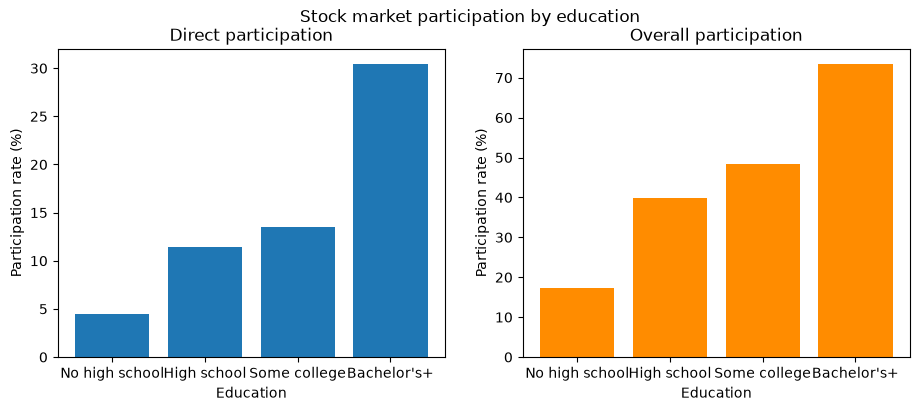

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(educ_names, direct_by_educ)
axes[0].set_title('Direct participation')
axes[0].set_xlabel('Education')
axes[0].set_ylabel('Participation rate (%)')

axes[1].bar(educ_names, overall_by_educ, color='darkorange')
axes[1].set_title('Overall participation')
axes[1].set_xlabel('Education')
axes[1].set_ylabel('Participation rate (%)')

fig.suptitle('Stock market participation by education')
plt.show()


### 3.4 Education pattern

Participation increases with education for both measures. Only 4.4% of households without a high school degree hold stocks directly, compared with 30.5% of households with a bachelor's degree or higher. The overall rate rises from 17.3% to 73.5%, so most highly educated households hold some equity, mainly indirectly.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

### 4.1 Participation rates by year

In [11]:
# Get the survey years from the data (each year added once)
years = []
for year in df['year']:
    if year not in years:
        years.append(year)

direct_by_year = []
overall_by_year = []

for year in years:
    group = df.loc[df['year'] == year]
    direct_by_year.append(participation_rate(group['direct']))
    overall_by_year.append(participation_rate(group['overall']))

for i in range(len(years)):
    print(f'{years[i]}: direct {direct_by_year[i]:.1f}%, overall {overall_by_year[i]:.1f}%')


1989: direct 15.6%, overall 31.6%
1992: direct 18.3%, overall 40.1%
1995: direct 15.7%, overall 45.9%
1998: direct 19.9%, overall 51.2%
2001: direct 21.8%, overall 57.0%
2004: direct 18.9%, overall 54.7%
2007: direct 17.3%, overall 56.5%
2010: direct 17.4%, overall 50.3%
2013: direct 14.8%, overall 49.9%
2016: direct 12.3%, overall 52.0%
2019: direct 12.4%, overall 49.8%
2022: direct 19.2%, overall 54.3%


### 4.2 Figure

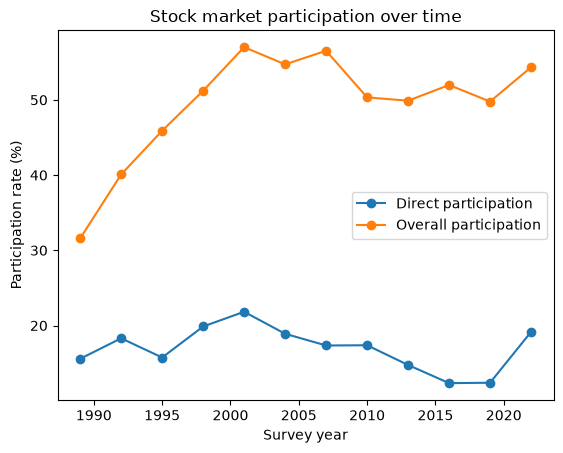

In [12]:
plt.plot(years, direct_by_year, marker='o', label='Direct participation')
plt.plot(years, overall_by_year, marker='o', label='Overall participation')
plt.title('Stock market participation over time')
plt.xlabel('Survey year')
plt.ylabel('Participation rate (%)')
plt.legend()
plt.show()


### 4.3 Change from 1989 to 2022

In [13]:
direct_change = direct_by_year[-1] - direct_by_year[0]
overall_change = overall_by_year[-1] - overall_by_year[0]

print(f'Change in direct participation: {direct_change:.1f} percentage points')
print(f'Change in overall participation: {overall_change:.1f} percentage points')


Change in direct participation: 3.6 percentage points
Change in overall participation: 22.8 percentage points


### 4.4 Time pattern

Overall participation rose strongly from 31.6% in 1989 to a peak of 57.0% in 2001 and has stayed roughly between 50% and 57% since then, ending at 54.3% in 2022. Direct participation changed much less: it peaked at 21.8% in 2001, fell to around 12% in 2016 and 2019, and rose again to 19.2% in 2022. The growth in participation therefore came mostly from indirect holdings such as mutual funds and retirement accounts.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used Claude (an AI assistant from Anthropic) to write the code and the short written answers in this notebook. I asked it to only use methods from lectures and workshops 1–3. I then read through the code and checked the results myself.